# Oil Spill Semantic Segmentation — Member 1
**Scope:** Data preprocessing + **U-Net (from scratch), Experiment 1: unweighted Cross-Entropy loss**.

Pipeline: inspect dataset and verify the RGB-to-class mapping → convert RGB masks to integer labels →
seeded train/validation split from the official training set → train U-Net with cross-entropy →
pick the checkpoint with the best **validation mIoU** → one final evaluation on the untouched official test set.

Run on Kaggle with a **GPU** accelerator and the dataset `nabilsherif/oil-spill` added as input.
Use *Save Version → Save & Run All* for the full run. All artifacts are saved under `/kaggle/working/outputs`.

## 1. Configuration and dataset paths

In [1]:
import os, sys, glob, json
from pathlib import Path

ON_KAGGLE = Path('/kaggle/working').exists()
WORK = Path('/kaggle/working') if ON_KAGGLE else Path(os.environ.get('OILSPILL_WORK', Path.cwd()))
INPUT = Path('/kaggle/input') if ON_KAGGLE else Path(os.environ.get('OILSPILL_DATA', Path.cwd() / 'dataset'))

def find_split(split):
    # Locate <split>/images and its RGB mask folder (labels or masks; not labels_1D).
    for images in sorted(INPUT.rglob('images')):
        if images.is_dir() and images.parent.name.lower() == split:
            for name in ('labels', 'masks', 'label', 'mask'):
                masks = images.parent / name
                if masks.is_dir():
                    return images, masks
    raise FileNotFoundError(f'Could not find {split}/images + RGB mask folder under {INPUT}')

TRAIN_IMAGES, TRAIN_MASKS = find_split('train')
TEST_IMAGES, TEST_MASKS = find_split('test')
for p in (TRAIN_IMAGES, TRAIN_MASKS, TEST_IMAGES, TEST_MASKS):
    print(p, '->', len(list(p.iterdir())), 'files')

# Experiment settings (kept fixed for a fair comparison with the other U-Net experiment)
EPOCHS = 30
BATCH_SIZE = 8
IMAGE_SIZE = 256
LEARNING_RATE = 1e-3
SEED = 42
COLOR_TOLERANCE = -1  # -1: snap blended edge colors in masks to the nearest class color (0 = exact only, errors on noise)
OUT = WORK / 'outputs' / 'unet_ce'
os.environ['PYTHONPATH'] = str(WORK / 'src')

/kaggle/input/datasets/nabilsherif/oil-spill/oil-spill/train/images -> 1002 files
/kaggle/input/datasets/nabilsherif/oil-spill/oil-spill/train/labels -> 1002 files
/kaggle/input/datasets/nabilsherif/oil-spill/oil-spill/test/images -> 110 files
/kaggle/input/datasets/nabilsherif/oil-spill/oil-spill/test/labels -> 110 files


## 2. Source code
The cells below write the project modules to disk so they can be run as scripts (robust for *Save & Run All*).

In [2]:
for sub in ('src/oilspill', 'scripts'):
    (WORK / sub).mkdir(parents=True, exist_ok=True)

In [3]:
%%writefile {WORK}/src/oilspill/__init__.py
"""Oil-spill semantic segmentation utilities."""

CLASS_NAMES = ("sea", "oil_spill", "look_alike", "ship", "land")
CLASS_COLORS = (
    (0, 0, 0),
    (0, 255, 255),
    (255, 0, 0),
    (153, 76, 0),
    (0, 153, 0),
)
NUM_CLASSES = len(CLASS_NAMES)

Writing /kaggle/working/src/oilspill/__init__.py


In [4]:
%%writefile {WORK}/src/oilspill/data.py
"""Dataset pairing, RGB-mask conversion, preprocessing, and paired augmentation."""

from __future__ import annotations

import random
from pathlib import Path
from typing import Sequence

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

from . import CLASS_COLORS, NUM_CLASSES

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
_COLOR_TO_ID = {color: index for index, color in enumerate(CLASS_COLORS)}


def pair_files(image_dir: str | Path, mask_dir: str | Path) -> list[tuple[Path, Path]]:
    """Pair images and masks by relative path and filename stem."""
    image_root, mask_root = Path(image_dir), Path(mask_dir)
    if not image_root.is_dir() or not mask_root.is_dir():
        raise FileNotFoundError(f"Expected image and mask directories: {image_root}, {mask_root}")

    def indexed_files(root: Path) -> dict[str, Path]:
        indexed: dict[str, Path] = {}
        for path in sorted(root.rglob("*")):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                key = path.relative_to(root).with_suffix("").as_posix().casefold()
                if key in indexed:
                    raise ValueError(f"Duplicate file stem under {root}: {key}")
                indexed[key] = path
        return indexed

    images, masks = indexed_files(image_root), indexed_files(mask_root)
    missing_masks = sorted(images.keys() - masks.keys())
    missing_images = sorted(masks.keys() - images.keys())
    if missing_masks or missing_images:
        raise ValueError(
            f"Image/mask file mismatch. Missing masks for {missing_masks[:5]}; "
            f"missing images for {missing_images[:5]}"
        )
    if not images:
        raise ValueError(f"No supported image files found in {image_root}")
    return [(images[key], masks[key]) for key in sorted(images)]


def rgb_mask_to_labels(
    mask: np.ndarray, path: str | Path = "<mask>", tolerance: int = 0
) -> np.ndarray:
    """Convert an RGB color mask into class IDs.

    tolerance == 0: only exact palette colors are accepted (anything else raises).
    tolerance  > 0: a pixel is snapped to its nearest palette color if every channel is
                    within ``tolerance`` of it; otherwise it raises.
    tolerance  < 0: every pixel is snapped to the nearest palette color (Euclidean RGB
                    distance). Use this when masks contain blended edge colors from
                    anti-aliasing or lossy saving, e.g. (182, 15, 15) between red and black.
    """
    if mask.ndim != 3 or mask.shape[2] < 3:
        raise ValueError(f"Expected an RGB mask at {path}; got shape {mask.shape}")
    rgb = np.asarray(mask[..., :3], dtype=np.uint8)
    labels = np.full(rgb.shape[:2], 255, dtype=np.uint8)
    if tolerance == 0:
        for color, class_id in _COLOR_TO_ID.items():
            labels[np.all(rgb == color, axis=-1)] = class_id
    else:
        palette = np.asarray(CLASS_COLORS, dtype=np.int32)
        diff = rgb.astype(np.int32)[..., None, :] - palette
        nearest = (diff**2).sum(axis=-1).argmin(axis=-1)
        if tolerance > 0:
            worst_channel = np.abs(diff).max(axis=-1)
            within = np.take_along_axis(worst_channel, nearest[..., None], axis=-1)[..., 0] <= tolerance
        else:
            within = np.ones(nearest.shape, dtype=bool)
        labels[within] = nearest[within].astype(np.uint8)
    unknown = np.unique(rgb[labels == 255], axis=0)
    if unknown.size:
        examples = [tuple(int(channel) for channel in color) for color in unknown[:8]]
        raise ValueError(
            f"Unrecognized RGB colors in {path}: {examples}. Check the dataset's exact mask colors."
        )
    return labels


def split_pairs(
    pairs: Sequence[tuple[Path, Path]], validation_fraction: float = 0.15, seed: int = 42
) -> tuple[list[tuple[Path, Path]], list[tuple[Path, Path]]]:
    """Create deterministic train/validation subsets from official training files."""
    if not 0.0 < validation_fraction < 1.0:
        raise ValueError("validation_fraction must be between 0 and 1")
    if len(pairs) < 2:
        raise ValueError("At least two image/mask pairs are required for a train/validation split")
    indices = list(range(len(pairs)))
    random.Random(seed).shuffle(indices)
    validation_count = max(1, min(len(pairs) - 1, round(len(pairs) * validation_fraction)))
    validation_ids = set(indices[:validation_count])
    train = [pair for index, pair in enumerate(pairs) if index not in validation_ids]
    validation = [pair for index, pair in enumerate(pairs) if index in validation_ids]
    return train, validation


class OilSpillDataset(Dataset):
    """Load aligned image/mask pairs and return normalized image and integer labels."""

    def __init__(
        self,
        pairs: Sequence[tuple[Path, Path]],
        image_size: int = 256,
        augment: bool = False,
        color_tolerance: int = 0,
    ) -> None:
        if image_size < 16:
            raise ValueError("image_size must be at least 16 for the four-level U-Net")
        self.pairs = list(pairs)
        self.image_size = image_size
        self.augment = augment
        self.color_tolerance = color_tolerance

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as source:
            image = source.convert("RGB")
        with Image.open(mask_path) as source:
            mask = source.convert("RGB")
        if image.size != mask.size:
            raise ValueError(
                f"Image/mask dimensions differ for {image_path.name}: {image.size} vs {mask.size}"
            )

        size = (self.image_size, self.image_size)
        image = image.resize(size, Image.Resampling.BILINEAR)
        mask = mask.resize(size, Image.Resampling.NEAREST)
        image_array = np.asarray(image, dtype=np.float32) / 255.0
        label_array = rgb_mask_to_labels(np.asarray(mask), mask_path, self.color_tolerance)

        image_tensor = torch.from_numpy(image_array.copy()).permute(2, 0, 1)
        label_tensor = torch.from_numpy(label_array.astype(np.int64, copy=False))
        if self.augment:
            if random.random() < 0.5:
                image_tensor = image_tensor.flip(-1)
                label_tensor = label_tensor.flip(-1)
            if random.random() < 0.5:
                image_tensor = image_tensor.flip(-2)
                label_tensor = label_tensor.flip(-2)
            turns = random.randrange(4)
            if turns:
                image_tensor = torch.rot90(image_tensor, turns, (-2, -1))
                label_tensor = torch.rot90(label_tensor, turns, (-2, -1))
        return image_tensor, label_tensor


def class_pixel_counts(
    pairs: Sequence[tuple[Path, Path]], color_tolerance: int = 0
) -> tuple[np.ndarray, dict[tuple[int, int], int]]:
    """Count mask pixels by class and return original dimensions per pair."""
    counts = np.zeros(NUM_CLASSES, dtype=np.int64)
    dimensions: dict[tuple[int, int], int] = {}
    for image_path, mask_path in pairs:
        with Image.open(image_path) as source:
            image_size = source.size
        with Image.open(mask_path) as source:
            mask = source.convert("RGB")
        if image_size != mask.size:
            raise ValueError(
                f"Image/mask dimensions differ for {image_path.name}: {image_size} vs {mask.size}"
            )
        dimensions[mask.size] = dimensions.get(mask.size, 0) + 1
        labels = rgb_mask_to_labels(np.asarray(mask), mask_path, color_tolerance)
        counts += np.bincount(labels.reshape(-1), minlength=NUM_CLASSES)
    return counts, dimensions


def find_unknown_colors(pairs: Sequence[tuple[Path, Path]], limit: int = 20) -> dict[tuple[int, int, int], int]:
    """Return non-palette mask colors and how many pixels use them (for dataset inspection)."""
    palette = set(CLASS_COLORS)
    found: dict[tuple[int, int, int], int] = {}
    for _, mask_path in pairs:
        with Image.open(mask_path) as source:
            rgb = np.asarray(source.convert("RGB")).reshape(-1, 3)
        colors, counts = np.unique(rgb, axis=0, return_counts=True)
        for color, count in zip(colors, counts):
            key = tuple(int(channel) for channel in color)
            if key not in palette:
                found[key] = found.get(key, 0) + int(count)
    return dict(sorted(found.items(), key=lambda item: -item[1])[:limit])

Writing /kaggle/working/src/oilspill/data.py


In [5]:
%%writefile {WORK}/src/oilspill/metrics.py
"""Confusion-matrix based segmentation metrics shared by training and evaluation."""

from __future__ import annotations

import torch

from . import NUM_CLASSES


def update_confusion(confusion: torch.Tensor, labels: torch.Tensor, predictions: torch.Tensor) -> None:
    """Accumulate a (true class, predicted class) pixel-count matrix in place."""
    encoded = labels.reshape(-1) * NUM_CLASSES + predictions.reshape(-1)
    confusion += torch.bincount(encoded, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)


def metrics_from_confusion(confusion: torch.Tensor) -> dict[str, object]:
    """Pixel accuracy, per-class IoU/Dice, and their means (classes absent from both GT and
    predictions are reported as None and excluded from the mean)."""
    confusion = confusion.double().cpu()
    true_positive = confusion.diag()
    predicted = confusion.sum(0)
    actual = confusion.sum(1)
    union = predicted + actual - true_positive
    denominator = predicted + actual
    iou = torch.where(union > 0, true_positive / union.clamp_min(1), torch.nan)
    dice = torch.where(denominator > 0, 2 * true_positive / denominator.clamp_min(1), torch.nan)
    return {
        "pixel_accuracy": float(true_positive.sum() / confusion.sum().clamp_min(1)),
        "miou": float(torch.nanmean(iou)),
        "mean_dice": float(torch.nanmean(dice)),
        "class_iou": [None if torch.isnan(v) else float(v) for v in iou],
        "class_dice": [None if torch.isnan(v) else float(v) for v in dice],
    }

Writing /kaggle/working/src/oilspill/metrics.py


In [6]:
%%writefile {WORK}/src/oilspill/unet.py
"""A compact U-Net trained from scratch for five-class segmentation."""

from __future__ import annotations

import torch
from torch import nn
from torch.nn import functional as F


class ConvBlock(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )


class UNet(nn.Module):
    """Four-level U-Net; returns raw logits with the same height and width as input."""

    def __init__(self, in_channels: int = 3, num_classes: int = 5, base_channels: int = 32) -> None:
        super().__init__()
        c1, c2, c3, c4, c5 = (base_channels * factor for factor in (1, 2, 4, 8, 16))
        self.enc1 = ConvBlock(in_channels, c1)
        self.enc2 = ConvBlock(c1, c2)
        self.enc3 = ConvBlock(c2, c3)
        self.enc4 = ConvBlock(c3, c4)
        self.bottleneck = ConvBlock(c4, c5)
        self.pool = nn.MaxPool2d(2)
        self.up4 = nn.ConvTranspose2d(c5, c4, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(c4 * 2, c4)
        self.up3 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(c3 * 2, c3)
        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(c2 * 2, c2)
        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(c1 * 2, c1)
        self.classifier = nn.Conv2d(c1, num_classes, kernel_size=1)

    @staticmethod
    def _merge(up: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        if up.shape[-2:] != skip.shape[-2:]:
            up = F.interpolate(up, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return torch.cat((skip, up), dim=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        center = self.bottleneck(self.pool(x4))
        x = self.dec4(self._merge(self.up4(center), x4))
        x = self.dec3(self._merge(self.up3(x), x3))
        x = self.dec2(self._merge(self.up2(x), x2))
        x = self.dec1(self._merge(self.up1(x), x1))
        return self.classifier(x)

Writing /kaggle/working/src/oilspill/unet.py


In [7]:
%%writefile {WORK}/src/oilspill/train_unet_ce.py
"""Train U-Net Experiment 1 with unweighted pixel-wise cross-entropy loss."""

from __future__ import annotations

import argparse
import csv
import json
import random
import time
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader

from . import CLASS_COLORS, CLASS_NAMES, NUM_CLASSES
from .data import OilSpillDataset, pair_files, split_pairs
from .metrics import metrics_from_confusion, update_confusion
from .unet import UNet

HISTORY_FIELDS = [
    "epoch", "train_loss", "train_pixel_accuracy", "train_miou", "train_mean_dice",
    "val_loss", "val_pixel_accuracy", "val_miou", "val_mean_dice",
    *[f"val_iou_{name}" for name in CLASS_NAMES],
    "learning_rate", "seconds",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    optimizer: torch.optim.Optimizer | None = None,
) -> dict[str, object]:
    training = optimizer is not None
    model.train(training)
    total_loss, total_pixels = 0.0, 0
    confusion = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += float(loss.detach()) * labels.numel()
            total_pixels += labels.numel()
            update_confusion(confusion, labels, logits.argmax(dim=1))
    metrics = metrics_from_confusion(confusion)
    metrics["loss"] = total_loss / max(total_pixels, 1)
    return metrics


def write_history(history: list[dict[str, object]], output_dir: Path, best_epoch: int) -> None:
    with (output_dir / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=HISTORY_FIELDS)
        writer.writeheader()
        for row in history:
            writer.writerow({field: row[field] for field in HISTORY_FIELDS})
    (output_dir / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")

    epochs = [int(row["epoch"]) for row in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(epochs, [row["train_loss"] for row in history], label="Train")
    axes[0].plot(epochs, [row["val_loss"] for row in history], label="Validation")
    axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
    axes[1].plot(epochs, [row["train_miou"] for row in history], label="Train mIoU")
    axes[1].plot(epochs, [row["val_miou"] for row in history], label="Validation mIoU")
    axes[1].plot(epochs, [row["train_mean_dice"] for row in history], "--", label="Train mean Dice")
    axes[1].plot(epochs, [row["val_mean_dice"] for row in history], "--", label="Validation mean Dice")
    axes[1].set(title="Class-sensitive metrics", xlabel="Epoch", ylabel="Score", ylim=(0, 1))
    for name in CLASS_NAMES:
        values = [np.nan if row[f"val_iou_{name}"] is None else row[f"val_iou_{name}"] for row in history]
        axes[2].plot(epochs, values, label=name)
    axes[2].set(title="Validation IoU per class", xlabel="Epoch", ylabel="IoU", ylim=(0, 1))
    for axis in axes:
        axis.axvline(best_epoch, color="grey", linestyle=":", linewidth=1)
        axis.grid(alpha=0.25)
        axis.legend(fontsize=8)
    fig.suptitle(f"U-Net Exp. 1 (cross-entropy) - best epoch {best_epoch} by validation mIoU")
    fig.tight_layout()
    fig.savefig(output_dir / "training_curves.png", dpi=160)
    plt.close(fig)


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train-images", type=Path, required=True, help="Official training image directory")
    parser.add_argument("--train-masks", type=Path, required=True, help="Official training mask directory")
    parser.add_argument("--output", type=Path, default=Path("outputs/unet_ce"))
    parser.add_argument("--image-size", type=int, default=256)
    parser.add_argument("--batch-size", type=int, default=8)
    parser.add_argument("--epochs", type=int, default=30)
    parser.add_argument("--learning-rate", type=float, default=1e-3)
    parser.add_argument("--validation-fraction", type=float, default=0.15)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--num-workers", type=int, default=0)
    parser.add_argument("--color-tolerance", type=int, default=0,
                        help="0 = exact palette; N>0 = snap within N per channel; -1 = snap to nearest class color")
    parser.add_argument("--resume", action="store_true",
                        help="Continue from <output>/last_checkpoint.pt if it exists")
    args = parser.parse_args()
    if args.epochs < 1 or args.batch_size < 1 or args.learning_rate <= 0:
        parser.error("epochs, batch-size, and learning-rate must be positive")

    seed_everything(args.seed)
    pairs = pair_files(args.train_images, args.train_masks)
    train_pairs, validation_pairs = split_pairs(pairs, args.validation_fraction, args.seed)
    loader_kwargs = {"batch_size": args.batch_size, "num_workers": args.num_workers,
                     "pin_memory": torch.cuda.is_available()}
    train_loader = DataLoader(
        OilSpillDataset(train_pairs, args.image_size, augment=True, color_tolerance=args.color_tolerance),
        shuffle=True, generator=torch.Generator().manual_seed(args.seed), **loader_kwargs,
    )
    validation_loader = DataLoader(
        OilSpillDataset(validation_pairs, args.image_size, augment=False, color_tolerance=args.color_tolerance),
        shuffle=False, **loader_kwargs,
    )
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = UNet(num_classes=NUM_CLASSES).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate)
    args.output.mkdir(parents=True, exist_ok=True)

    experiment_config = {
        "experiment": "U-Net from scratch - unweighted cross-entropy",
        "image_size": args.image_size,
        "batch_size": args.batch_size,
        "epochs": args.epochs,
        "learning_rate": args.learning_rate,
        "optimizer": "Adam",
        "loss": "CrossEntropyLoss (unweighted)",
        "normalization": "RGB scaled to [0, 1]; no mean/std normalization (no pretrained weights)",
        "augmentation": "train only: random horizontal/vertical flips and 90-degree rotations",
        "checkpoint_rule": "highest validation mIoU",
        "validation_fraction": args.validation_fraction,
        "seed": args.seed,
        "color_tolerance": args.color_tolerance,
        "parameter_count": sum(p.numel() for p in model.parameters()),
        "train_pair_count": len(train_pairs),
        "validation_pair_count": len(validation_pairs),
        "classes": [
            {"id": class_id, "name": name, "rgb": list(color)}
            for class_id, (name, color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS))
        ],
        "train_files": [image.relative_to(args.train_images).as_posix() for image, _ in train_pairs],
        "validation_files": [image.relative_to(args.train_images).as_posix() for image, _ in validation_pairs],
        "device": str(device) + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""),
    }
    (args.output / "config.json").write_text(json.dumps(experiment_config, indent=2), encoding="utf-8")

    best_miou, best_epoch, history, start_epoch = -1.0, 0, [], 1
    last_path = args.output / "last_checkpoint.pt"
    if args.resume and last_path.exists():
        state = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        best_miou, best_epoch, history = state["best_miou"], state["best_epoch"], state["history"]
        random.setstate(state["python_random_state"])
        # map_location=device moves every tensor to the GPU, but set_rng_state needs a CPU ByteTensor
        torch.set_rng_state(state["torch_rng_state"].cpu())
        start_epoch = state["epoch"] + 1
        print(f"Resumed from epoch {state['epoch']} (best val mIoU {best_miou:.4f} at epoch {best_epoch})")

    print(f"Device: {experiment_config['device']}; training pairs: {len(train_pairs)}; "
          f"validation pairs: {len(validation_pairs)}")
    print(f"Input: {args.image_size}x{args.image_size}; loss: unweighted CrossEntropyLoss; seed: {args.seed}")
    run_started = time.perf_counter()
    for epoch in range(start_epoch, args.epochs + 1):
        started = time.perf_counter()
        train_metrics = run_epoch(model, train_loader, criterion, device, optimizer)
        val_metrics = run_epoch(model, validation_loader, criterion, device)
        elapsed = time.perf_counter() - started
        row: dict[str, object] = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_pixel_accuracy": train_metrics["pixel_accuracy"],
            "train_miou": train_metrics["miou"],
            "train_mean_dice": train_metrics["mean_dice"],
            "val_loss": val_metrics["loss"],
            "val_pixel_accuracy": val_metrics["pixel_accuracy"],
            "val_miou": val_metrics["miou"],
            "val_mean_dice": val_metrics["mean_dice"],
            **{f"val_iou_{name}": value for name, value in zip(CLASS_NAMES, val_metrics["class_iou"])},
            "val_class_dice": val_metrics["class_dice"],
            "learning_rate": optimizer.param_groups[0]["lr"],
            "seconds": round(elapsed, 2),
        }
        history.append(row)
        if float(val_metrics["miou"]) > best_miou:
            best_miou, best_epoch = float(val_metrics["miou"]), epoch
            torch.save(
                {"epoch": epoch, "model_state_dict": model.state_dict(), "val_miou": best_miou,
                 "class_names": CLASS_NAMES, "image_size": args.image_size, "seed": args.seed},
                args.output / "best_model.pt",
            )
        write_history(history, args.output, best_epoch)
        torch.save(
            {"epoch": epoch, "model_state_dict": model.state_dict(),
             "optimizer_state_dict": optimizer.state_dict(), "best_miou": best_miou,
             "best_epoch": best_epoch, "history": history,
             "python_random_state": random.getstate(), "torch_rng_state": torch.get_rng_state()},
            last_path,
        )
        print(
            f"Epoch {epoch:02d}/{args.epochs} | train loss {train_metrics['loss']:.4f} "
            f"mIoU {train_metrics['miou']:.4f} | val loss {val_metrics['loss']:.4f} "
            f"mIoU {val_metrics['miou']:.4f} Dice {val_metrics['mean_dice']:.4f} | {elapsed:.1f}s"
        )
    total_seconds = sum(float(row["seconds"]) for row in history)
    summary = {"best_epoch": best_epoch, "best_val_miou": best_miou,
               "selection_rule": "highest validation mIoU", "epochs_run": len(history),
               "total_training_seconds": round(total_seconds, 1),
               "this_session_seconds": round(time.perf_counter() - run_started, 1)}
    (args.output / "training_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print(f"Best validation mIoU: {best_miou:.4f} at epoch {best_epoch}; "
          f"training time {total_seconds / 60:.1f} min; artifacts: {args.output.resolve()}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/src/oilspill/train_unet_ce.py


In [8]:
%%writefile {WORK}/src/oilspill/evaluate_unet.py
"""Final evaluation of a trained U-Net checkpoint on a held-out split (normally the official test set).

Writes metrics.json, per_class_metrics.csv, confusion_matrix.png, predictions.png
(representative examples), and failure_cases.png (oil/look-alike confusion and missed ships).
Run this only after model selection on the validation set is finished.
"""

from __future__ import annotations

import argparse
import csv
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from . import CLASS_COLORS, CLASS_NAMES, NUM_CLASSES
from .data import OilSpillDataset, pair_files
from .metrics import metrics_from_confusion, update_confusion
from .unet import UNet

OIL, LOOK_ALIKE, SHIP = 1, 2, 3
PALETTE = np.asarray(CLASS_COLORS, dtype=np.uint8)


def plot_confusion(confusion: np.ndarray, path: Path, title: str) -> None:
    row_totals = confusion.sum(axis=1, keepdims=True)
    normalized = np.divide(confusion, row_totals, out=np.zeros_like(confusion, dtype=float), where=row_totals > 0)
    fig, axis = plt.subplots(figsize=(6.5, 5.5))
    image = axis.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    axis.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=35, ha="right")
    axis.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    axis.set(xlabel="Predicted class", ylabel="True class", title=title)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axis.text(j, i, f"{normalized[i, j]:.2f}", ha="center", va="center",
                      color="white" if normalized[i, j] > 0.5 else "black", fontsize=8)
    fig.colorbar(image, ax=axis, label="Fraction of true-class pixels")
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.close(fig)


def plot_examples(samples: list[dict], path: Path, title: str) -> None:
    if not samples:
        return
    fig, axes = plt.subplots(len(samples), 3, figsize=(11, 3.3 * len(samples)), squeeze=False)
    for row, sample in enumerate(samples):
        axes[row, 0].imshow(sample["image"])
        axes[row, 0].set_title(f"SAR input: {sample['name']}", fontsize=9)
        axes[row, 1].imshow(PALETTE[sample["label"]])
        axes[row, 1].set_title("Ground truth", fontsize=9)
        axes[row, 2].imshow(PALETTE[sample["prediction"]])
        axes[row, 2].set_title(f"Prediction ({sample['note']})", fontsize=9)
        for axis in axes[row]:
            axis.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=np.asarray(c) / 255, ec="grey") for c in CLASS_COLORS]
    fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=NUM_CLASSES)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.03, 1, 0.98))
    fig.savefig(path, dpi=130)
    plt.close(fig)


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--checkpoint", type=Path, required=True)
    parser.add_argument("--images", type=Path, required=True, help="Held-out image directory (official test set)")
    parser.add_argument("--masks", type=Path, required=True, help="Held-out RGB mask directory")
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--split-name", default="test")
    parser.add_argument("--batch-size", type=int, default=8)
    parser.add_argument("--color-tolerance", type=int, default=0)
    parser.add_argument("--examples", type=int, default=4)
    args = parser.parse_args()

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    state = torch.load(args.checkpoint, map_location=device, weights_only=False)
    model = UNet(num_classes=NUM_CLASSES).to(device)
    model.load_state_dict(state["model_state_dict"])
    model.eval()
    pairs = pair_files(args.images, args.masks)
    dataset = OilSpillDataset(pairs, state["image_size"], augment=False, color_tolerance=args.color_tolerance)
    loader = DataLoader(dataset, batch_size=args.batch_size, shuffle=False)
    args.output.mkdir(parents=True, exist_ok=True)

    confusion = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)
    per_image: list[dict] = []
    index = 0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images).argmax(dim=1)
            update_confusion(confusion, labels, predictions)
            for label, prediction in zip(labels, predictions):
                oil_lookalike = int(((label == OIL) & (prediction == LOOK_ALIKE)).sum()
                                    + ((label == LOOK_ALIKE) & (prediction == OIL)).sum())
                ship_pixels = int((label == SHIP).sum())
                ship_hits = int(((label == SHIP) & (prediction == SHIP)).sum())
                per_image.append({
                    "index": index, "name": pairs[index][0].name,
                    "pixel_accuracy": float((label == prediction).float().mean()),
                    "oil_lookalike_confusion": oil_lookalike,
                    "ship_pixels": ship_pixels,
                    "ship_recall": ship_hits / ship_pixels if ship_pixels else None,
                })
                index += 1

    metrics = metrics_from_confusion(confusion)
    confusion_np = confusion.cpu().numpy()
    result = {"split": args.split_name, "checkpoint": str(args.checkpoint), "checkpoint_epoch": state["epoch"],
              "image_count": len(pairs), **metrics, "confusion_matrix": confusion_np.tolist(),
              "class_names": list(CLASS_NAMES)}
    (args.output / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    with (args.output / "per_class_metrics.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["class_id", "class", "iou", "dice_f1", "gt_pixels", "predicted_pixels"])
        for class_id, name in enumerate(CLASS_NAMES):
            writer.writerow([class_id, name, metrics["class_iou"][class_id], metrics["class_dice"][class_id],
                             int(confusion_np[class_id].sum()), int(confusion_np[:, class_id].sum())])
    plot_confusion(confusion_np, args.output / "confusion_matrix.png",
                   f"U-Net CE - {args.split_name} confusion (row-normalized)")

    def sample(entry: dict, note: str) -> dict:
        image, label = dataset[entry["index"]]
        with torch.inference_mode():
            prediction = model(image[None].to(device)).argmax(dim=1)[0].cpu().numpy()
        return {"image": image.permute(1, 2, 0).numpy(), "label": label.numpy(),
                "prediction": prediction, "name": entry["name"], "note": note}

    ranked = sorted(per_image, key=lambda e: e["pixel_accuracy"])
    picks = np.linspace(0, len(ranked) - 1, num=min(args.examples, len(ranked))).round().astype(int)
    representative = [sample(ranked[i], f"pixel acc {ranked[i]['pixel_accuracy']:.3f}") for i in picks]
    plot_examples(representative, args.output / "predictions.png",
                  f"Representative {args.split_name} predictions (worst to best pixel accuracy)")

    confused = sorted((e for e in per_image if e["oil_lookalike_confusion"] > 0),
                      key=lambda e: -e["oil_lookalike_confusion"])[:2]
    missed_ships = sorted((e for e in per_image if e["ship_pixels"] > 0),
                          key=lambda e: e["ship_recall"])[:2]
    failures = ([sample(e, f"oil<->look-alike px {e['oil_lookalike_confusion']}") for e in confused]
                + [sample(e, f"ship recall {e['ship_recall']:.2f}") for e in missed_ships])
    plot_examples(failures, args.output / "failure_cases.png",
                  "Failure cases: oil/look-alike confusion and missed ships")
    (args.output / "per_image.json").write_text(json.dumps(per_image, indent=2), encoding="utf-8")

    print(f"{args.split_name}: {len(pairs)} images | mIoU {metrics['miou']:.4f} | "
          f"mean Dice {metrics['mean_dice']:.4f} | pixel accuracy {metrics['pixel_accuracy']:.4f}")
    for name, iou, dice in zip(CLASS_NAMES, metrics["class_iou"], metrics["class_dice"]):
        fmt = lambda v: "  n/a " if v is None else f"{v:.4f}"
        print(f"  {name:12s} IoU {fmt(iou)}  Dice {fmt(dice)}")
    print(f"Artifacts: {args.output.resolve()}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/src/oilspill/evaluate_unet.py


In [9]:
%%writefile {WORK}/scripts/inspect_dataset.py
"""Inspect paired samples, verify mask colors, summarize class balance, and save previews."""

from __future__ import annotations

import argparse
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

from oilspill import CLASS_COLORS, CLASS_NAMES
from oilspill.data import class_pixel_counts, find_unknown_colors, pair_files, rgb_mask_to_labels


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--images", type=Path, required=True)
    parser.add_argument("--masks", type=Path, required=True)
    parser.add_argument("--output", type=Path, default=Path("outputs/dataset_preview.png"))
    parser.add_argument("--samples", type=int, default=6)
    parser.add_argument("--color-tolerance", type=int, default=0,
                        help="0 = exact palette only; N>0 = snap colors within N per channel; -1 = snap every pixel to the nearest class color")
    args = parser.parse_args()
    if args.samples < 1:
        parser.error("samples must be positive")

    pairs = pair_files(args.images, args.masks)
    unknown = find_unknown_colors(pairs)
    if unknown:
        print("WARNING: mask colors outside the assignment palette (color: pixel count):")
        for color, count in unknown.items():
            print(f"  {color}: {count:,d}")
        if args.color_tolerance == 0:
            print("These look like blended/compressed edge colors. Use --color-tolerance -1 to snap each "
                  "pixel to the nearest class color (the training/evaluation scripts need the same flag).")
    else:
        print("All mask pixels use the exact assignment palette.")
    counts, dimensions = class_pixel_counts(pairs, args.color_tolerance)
    total = int(counts.sum())
    print(f"Validated {len(pairs)} image/mask pairs")
    print(f"Mask dimensions and image counts: {dimensions}")
    print("Class pixel distribution:")
    for class_id, (name, color, count) in enumerate(zip(CLASS_NAMES, CLASS_COLORS, counts)):
        fraction = 100.0 * int(count) / max(total, 1)
        print(f"  {class_id}: {name:12s} RGB={color} pixels={int(count):>12,d} ({fraction:6.3f}%)")

    preview_pairs = pairs[: min(args.samples, len(pairs))]
    fig, axes = plt.subplots(len(preview_pairs), 2, figsize=(8, 3.2 * len(preview_pairs)), squeeze=False)
    palette = np.asarray(CLASS_COLORS, dtype=np.uint8)
    for row, (image_path, mask_path) in enumerate(preview_pairs):
        with Image.open(image_path) as source:
            image = source.convert("RGB")
        with Image.open(mask_path) as source:
            raw_mask = np.asarray(source.convert("RGB"))
        labels = rgb_mask_to_labels(raw_mask, mask_path, args.color_tolerance)
        color_mask = palette[labels]
        axes[row, 0].imshow(image)
        axes[row, 0].set_title(f"Image: {image_path.name} ({image.width}x{image.height})")
        axes[row, 1].imshow(color_mask)
        axes[row, 1].set_title("Ground-truth mask")
        for axis in axes[row]:
            axis.axis("off")
    fig.tight_layout()
    args.output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(args.output, dpi=160)
    plt.close(fig)
    print(f"Preview saved to {args.output.resolve()}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/scripts/inspect_dataset.py


## 3. Dataset inspection
Checks image/mask pairing, image and mask dimensions, that every mask pixel uses one of the five palette
colors `(0,0,0) sea, (0,255,255) oil spill, (255,0,0) look-alike, (153,76,0) ship, (0,153,0) land`,
and the per-class pixel distribution (class imbalance).

In [10]:
!python {WORK}/scripts/inspect_dataset.py --images "{TRAIN_IMAGES}" --masks "{TRAIN_MASKS}" \
    --output {WORK}/outputs/dataset_preview.png --samples 6 --color-tolerance {COLOR_TOLERANCE}

All mask pixels use the exact assignment palette.
Validated 1002 image/mask pairs
Mask dimensions and image counts: {(1250, 650): 1002}
Class pixel distribution:
  0: sea          RGB=(0, 0, 0) pixels= 716,886,932 (88.056%)
  1: oil_spill    RGB=(0, 255, 255) pixels=   8,192,020 ( 1.006%)
  2: look_alike   RGB=(255, 0, 0) pixels=  45,832,926 ( 5.630%)
  3: ship         RGB=(153, 76, 0) pixels=     346,855 ( 0.043%)
  4: land         RGB=(0, 153, 0) pixels=  42,866,267 ( 5.265%)
Preview saved to /kaggle/working/outputs/dataset_preview.png


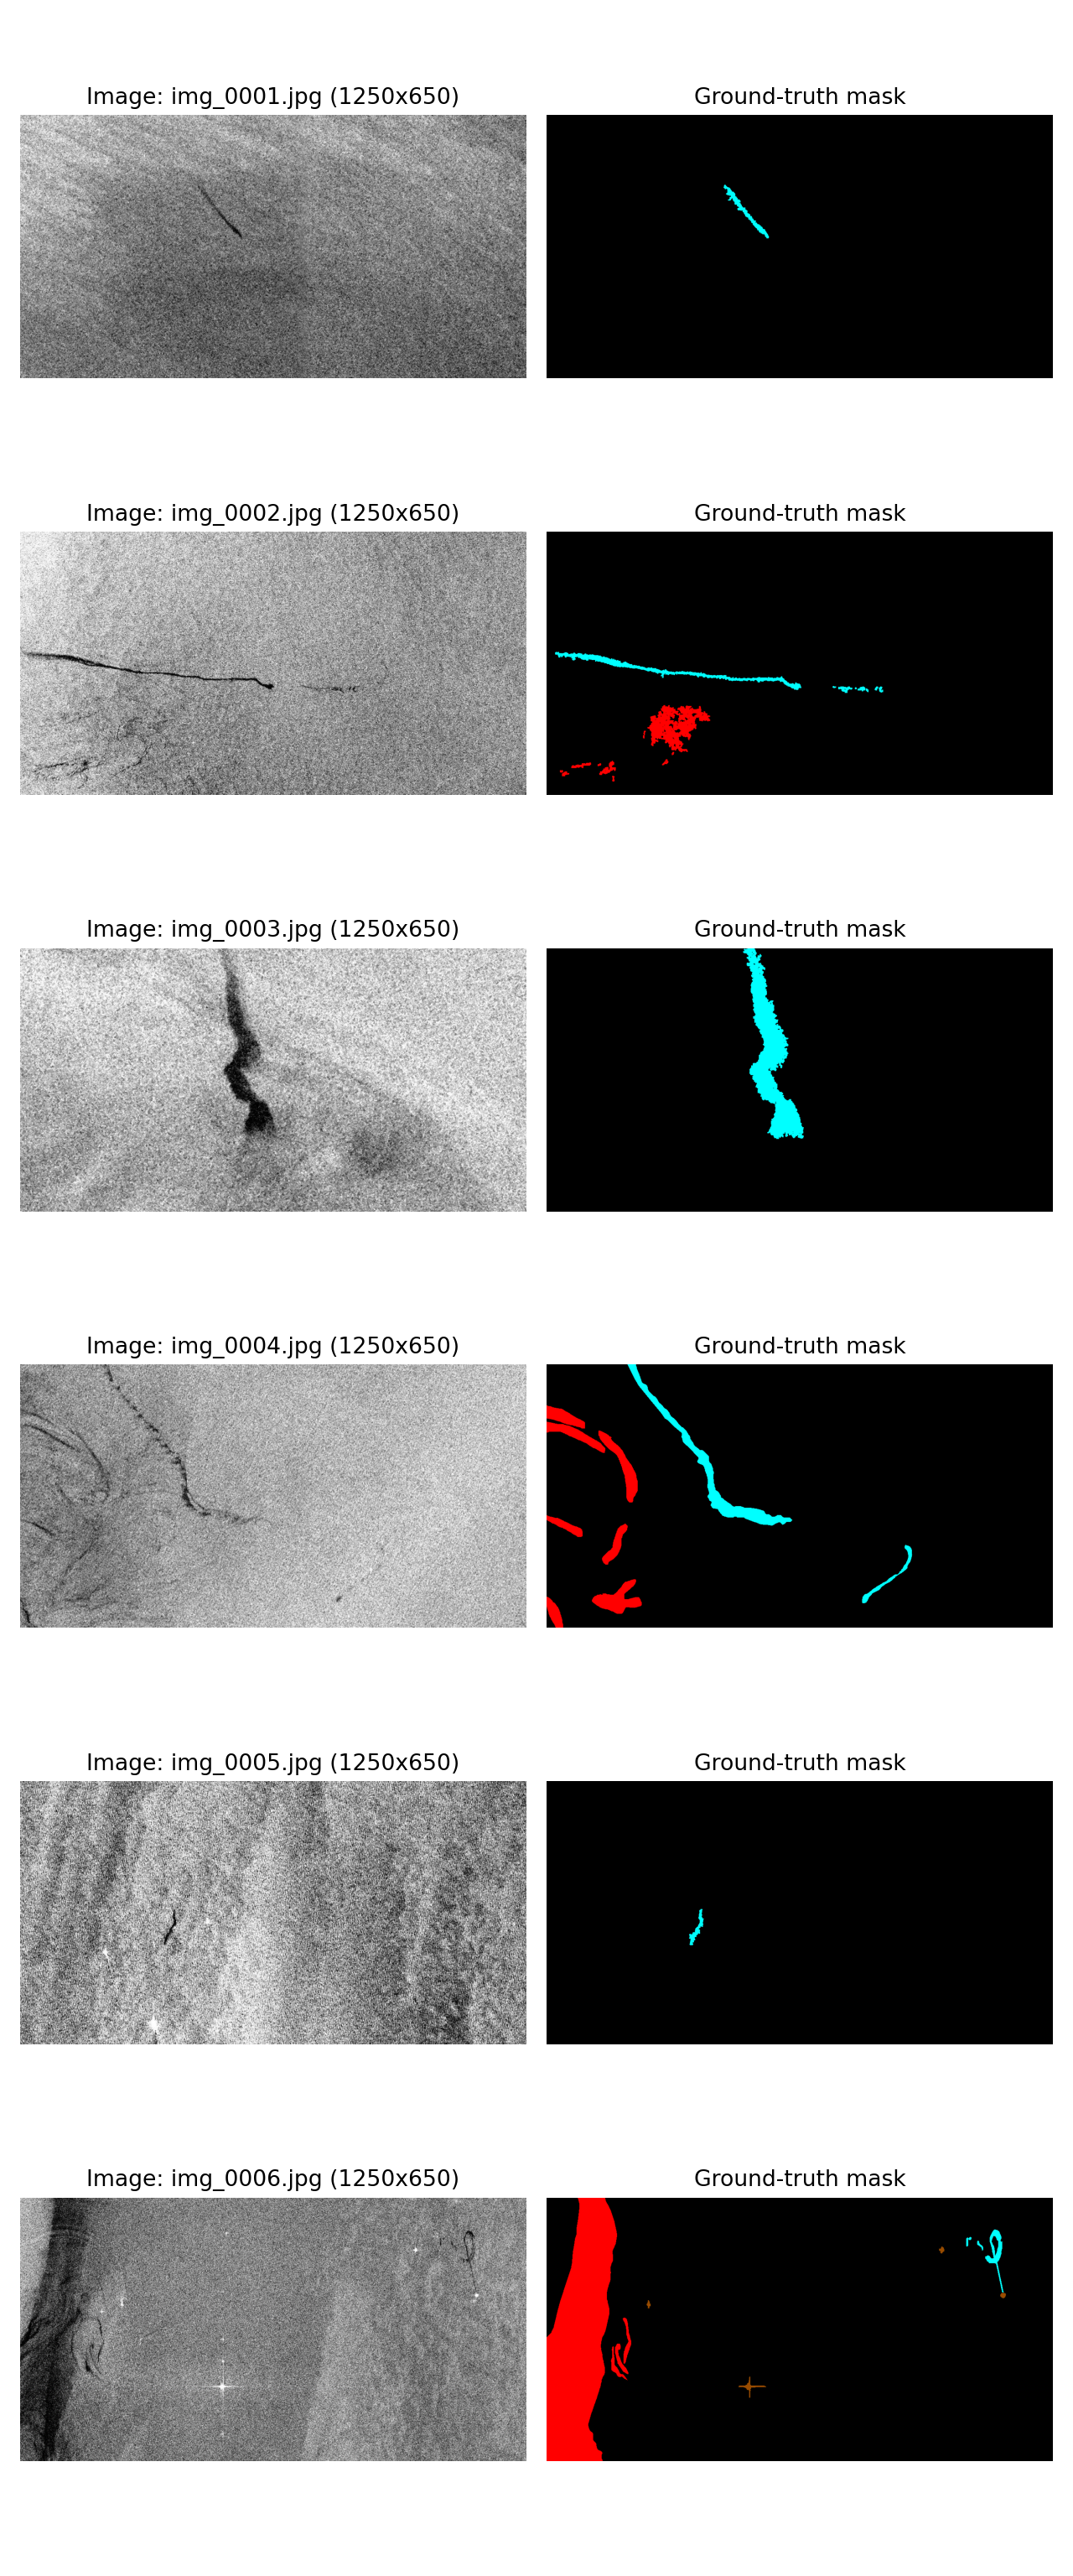

In [11]:
from IPython.display import Image as Show, display
display(Show(str(WORK / 'outputs/dataset_preview.png'), width=700))

**Preprocessing used**
- Images: loaded as 3-channel RGB, bilinear-resized to `IMAGE_SIZE`, scaled to `[0, 1]`. No ImageNet mean/std,
  since this U-Net has no pretrained weights.
- Masks: nearest-neighbor resized (class IDs never blended), converted RGB → single-channel integer labels 0–4.
  No normalization or color augmentation is applied to labels.
- Split: 85% / 15% train/validation from the official training set, seed 42. The official test set is used only in section 6.
- Augmentation (training only, applied identically to image and mask): random horizontal/vertical flip and 90° rotations.

## 4. U-Net architecture check
Encoder (4 levels) → bottleneck → decoder with skip connections → 1×1 conv to 5 class logits.

In [12]:
import subprocess, sys
src_dir = str(WORK / 'src')
check = f'''
import sys
sys.path.insert(0, {src_dir!r})
import torch
from oilspill.unet import UNet
model = UNet(num_classes=5).eval()
x = torch.randn(2, 3, {IMAGE_SIZE}, {IMAGE_SIZE})
with torch.no_grad():
    y = model(x)
print("input :", tuple(x.shape))
print("output:", tuple(y.shape), "-> (batch, 5 classes, H, W)")
print("predicted mask:", tuple(y.argmax(dim=1).shape))
assert y.shape[-2:] == x.shape[-2:] and y.shape[1] == 5
print(f"parameters: {{sum(p.numel() for p in model.parameters()):,}}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")
'''
result = subprocess.run([sys.executable, '-c', check], capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr[-3000:])

input : (2, 3, 256, 256)
output: (2, 5, 256, 256) -> (batch, 5 classes, H, W)
predicted mask: (2, 256, 256)
parameters: 7,763,173
GPU: Tesla T4



**Why skip connections?** Max-pooling discards spatial detail. Concatenating each encoder feature map with the
decoder map at the same resolution gives the decoder precise location and boundary information, which matters
for thin oil-spill edges and ships that are only a few pixels wide.

## 5. Training — Experiment 1: unweighted Cross-Entropy
**What it is:** standard pixel-wise cross-entropy, every pixel weighted equally. Adam, lr 1e-3.

**Why it may help or hurt:** it is stable and well calibrated, so it is a good baseline. But because sea and land
dominate the pixel count, the loss is minimized mostly by getting the large classes right; rare classes
(ship, oil spill) contribute little to the gradient and can be under-segmented. Pixel accuracy can look high
while ship/oil IoU stays low. This is the reference for the class-imbalance-aware experiments.

Checkpoints: `best_model.pt` (highest validation mIoU) and `last_checkpoint.pt` (every epoch, used by `--resume`).

In [13]:
!python -m oilspill.train_unet_ce --train-images "{TRAIN_IMAGES}" --train-masks "{TRAIN_MASKS}" \
    --output {OUT} --epochs {EPOCHS} --batch-size {BATCH_SIZE} --image-size {IMAGE_SIZE} \
    --learning-rate {LEARNING_RATE} --seed {SEED} --num-workers 2 --color-tolerance {COLOR_TOLERANCE} --resume

Device: cuda (Tesla T4); training pairs: 852; validation pairs: 150
Input: 256x256; loss: unweighted CrossEntropyLoss; seed: 42
Epoch 01/30 | train loss 0.7608 mIoU 0.2690 | val loss 1.6668 mIoU 0.2251 Dice 0.3049 | 41.2s
Epoch 02/30 | train loss 0.3770 mIoU 0.2655 | val loss 0.3157 mIoU 0.3280 Dice 0.4041 | 27.7s
Epoch 03/30 | train loss 0.3302 mIoU 0.2852 | val loss 0.2897 mIoU 0.3274 Dice 0.4177 | 28.5s
Epoch 04/30 | train loss 0.3058 mIoU 0.3040 | val loss 0.4844 mIoU 0.2761 Dice 0.3672 | 29.5s
Epoch 05/30 | train loss 0.2914 mIoU 0.3218 | val loss 0.2693 mIoU 0.3497 Dice 0.4388 | 29.9s
Epoch 06/30 | train loss 0.2975 mIoU 0.3153 | val loss 0.2251 mIoU 0.3539 Dice 0.4539 | 29.4s
Epoch 07/30 | train loss 0.2860 mIoU 0.3205 | val loss 0.2626 mIoU 0.3345 Dice 0.4235 | 29.5s
Epoch 08/30 | train loss 0.2780 mIoU 0.3350 | val loss 0.3232 mIoU 0.3332 Dice 0.4226 | 29.7s
Epoch 09/30 | train loss 0.2774 mIoU 0.3505 | val loss 0.2640 mIoU 0.3578 Dice 0.4554 | 29.5s
Epoch 10/30 | train loss 0

{
  "best_epoch": 25,
  "best_val_miou": 0.4785631626793251,
  "selection_rule": "highest validation mIoU",
  "epochs_run": 30,
  "total_training_seconds": 894.2,
  "this_session_seconds": 913.7
}


,epoch,train_loss,train_pixel_accuracy,train_miou,train_mean_dice,val_loss,val_pixel_accuracy,val_miou,val_mean_dice,val_iou_sea,val_iou_oil_spill,val_iou_look_alike,val_iou_ship,val_iou_land,learning_rate,seconds
0,1,0.7608,0.8553,0.2690,0.3423,1.6668,0.7063,0.2251,0.3049,0.6911,0.0000,0.2722,0.0,0.1623,0.001,41.23
1,2,0.3770,0.8873,0.2655,0.3326,0.3157,0.9058,0.3280,0.4041,0.9066,0.0000,0.3184,0.0,0.4150,0.001,27.72
2,3,0.3302,0.8941,0.2852,0.3610,0.2897,0.8993,0.3274,0.4177,0.8995,0.1524,0.1695,0.0,0.4156,0.001,28.49
3,4,0.3058,0.8974,0.3040,0.3892,0.4844,0.8167,0.2761,0.3672,0.8113,0.0972,0.2163,0.0,0.2557,0.001,29.48
4,5,0.2914,0.9001,0.3218,0.4138,0.2693,0.9083,0.3497,0.4388,0.9097,0.0730,0.3473,0.0,0.4184,0.001,29.90
5,6,0.2975,0.8965,0.3153,0.4074,0.2251,0.9223,0.3539,0.4539,0.9240,0.1996,0.3075,0.0,0.3384,0.001,29.37
6,7,0.2860,0.8996,0.3205,0.4140,0.2626,0.9156,0.3345,0.4235,0.9187,0.0950,0.3845,0.0,0.2745,0.001,29.54
7,8,0.2780,0.8995,0.3350,0.4323,0.3232,0.8991,0.3332,0.4226,0.8975,0.1629,0.1494,0.0,0.4562,0.001,29.68
8,9,0.2774,0.9027,0.3505,0.4512,0.2640,0.9034,0.3578,0.4554,0.9031,0.1665,0.2604,0.0,0.4590,0.001,29.48
9,10,0.2651,0.9080,0.3640,0.4657,0.2861,0.8921,0.3483,0.4415,0.8929,0.0941,0.3276,0.0,0.4271,0.001,29.49


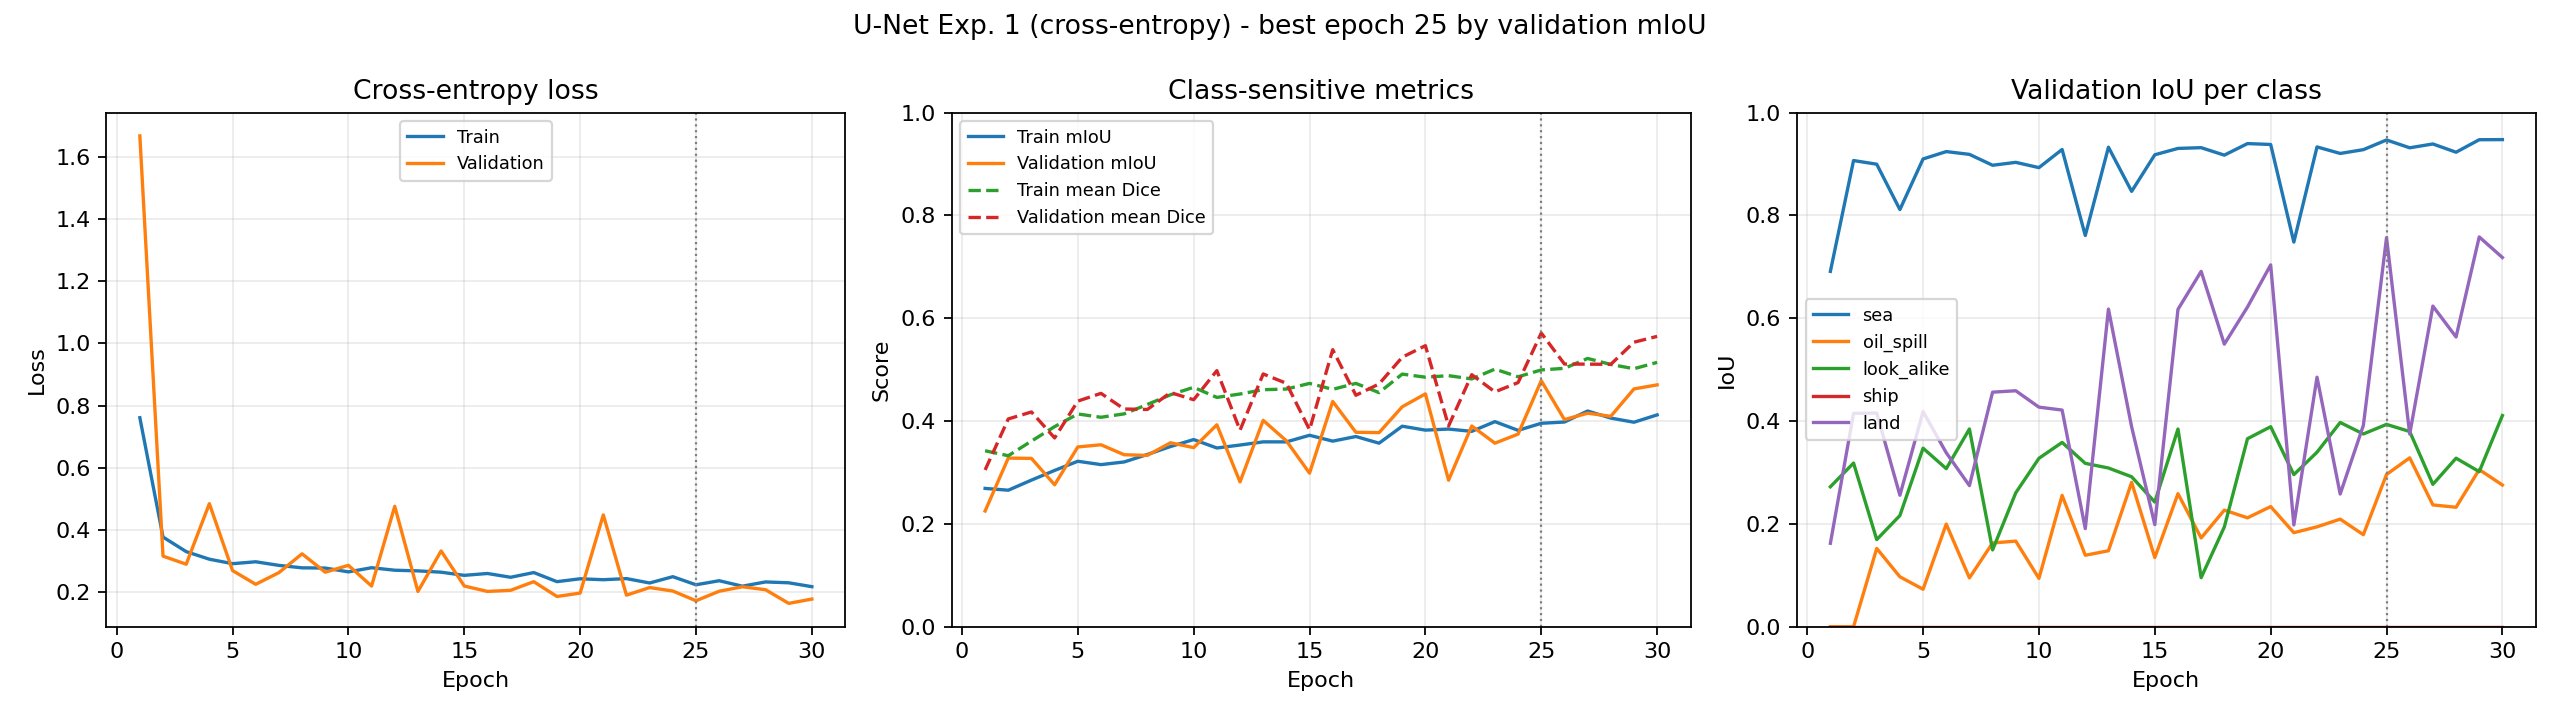

In [14]:
import pandas as pd
history = pd.read_csv(OUT / 'history.csv')
summary = json.loads((OUT / 'training_summary.json').read_text())
print(json.dumps(summary, indent=2))
display(history.round(4))
display(Show(str(OUT / 'training_curves.png'), width=1000))

**Training-curve discussion** *(fill in from the curves above — do not write this before the run finishes)*
- Selected epoch and rule: best validation mIoU (see `training_summary.json`).
- Train vs. validation loss: do they diverge (overfitting), both stay high (underfitting), or converge?
- Per-class validation IoU: which classes are learned late or not at all?
- Training time and compute limits:

## 6. Final evaluation on the official test set (run once, after model selection)

In [15]:
!python -m oilspill.evaluate_unet --checkpoint {OUT}/best_model.pt --images "{TEST_IMAGES}" \
    --masks "{TEST_MASKS}" --output {OUT}/test_eval --split-name test --color-tolerance {COLOR_TOLERANCE}

test: 110 images | mIoU 0.4365 | mean Dice 0.5282 | pixel accuracy 0.9190
  sea          IoU 0.9188  Dice 0.9577
  oil_spill    IoU 0.2243  Dice 0.3664
  look_alike   IoU 0.3100  Dice 0.4733
  ship         IoU 0.0000  Dice 0.0000
  land         IoU 0.7295  Dice 0.8436
Artifacts: /kaggle/working/outputs/unet_ce/test_eval


,class_id,class,iou,dice_f1,gt_pixels,predicted_pixels
0,0,sea,0.9188,0.9577,6525097,6358357
1,1,oil_spill,0.2243,0.3664,77107,40395
2,2,look_alike,0.3100,0.4733,373658,505425
3,3,ship,0.0000,0.0000,888,0
4,4,land,0.7295,0.8436,232210,304783


mIoU 0.4365 | mean Dice 0.5282 | pixel accuracy 0.9190 (supplementary)


,experiment,mIoU,mean_Dice,pixel_acc,IoU_sea,IoU_oil_spill,IoU_look_alike,IoU_ship,IoU_land
0,U-Net Exp.1 Cross-Entropy,0.4365,0.5282,0.919,0.9188,0.2243,0.31,0.0,0.7295


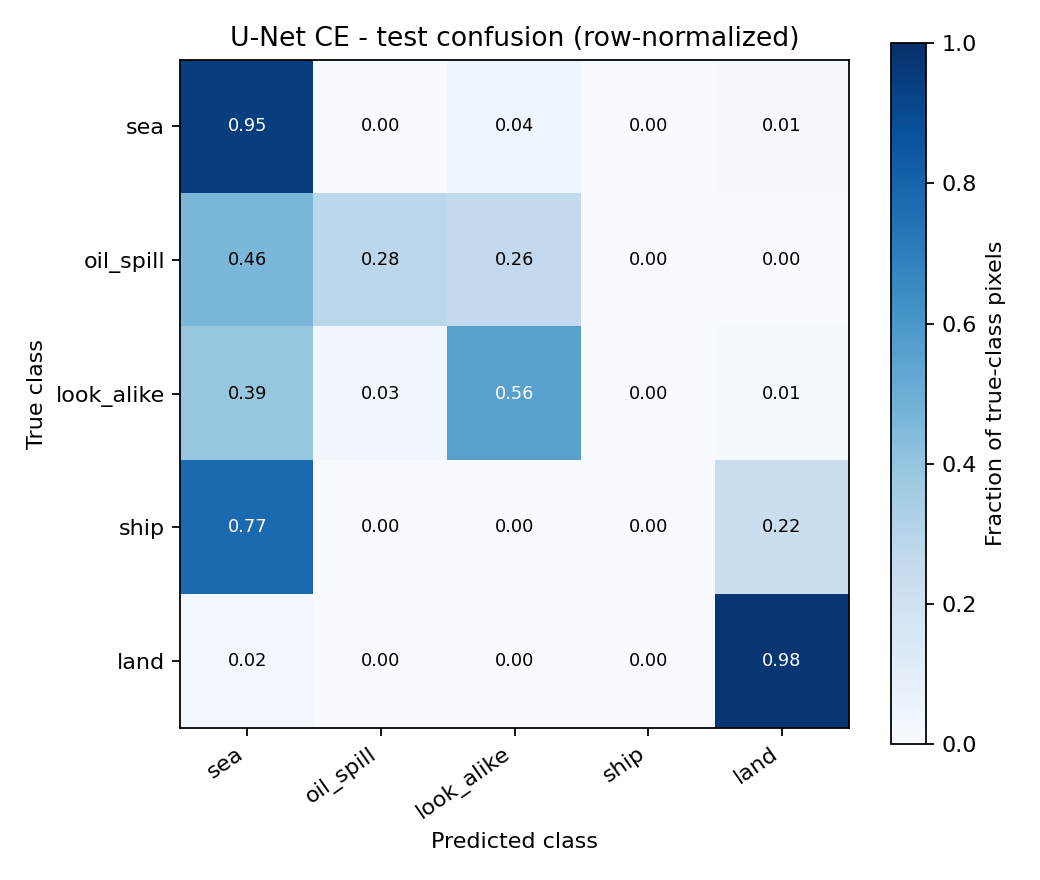

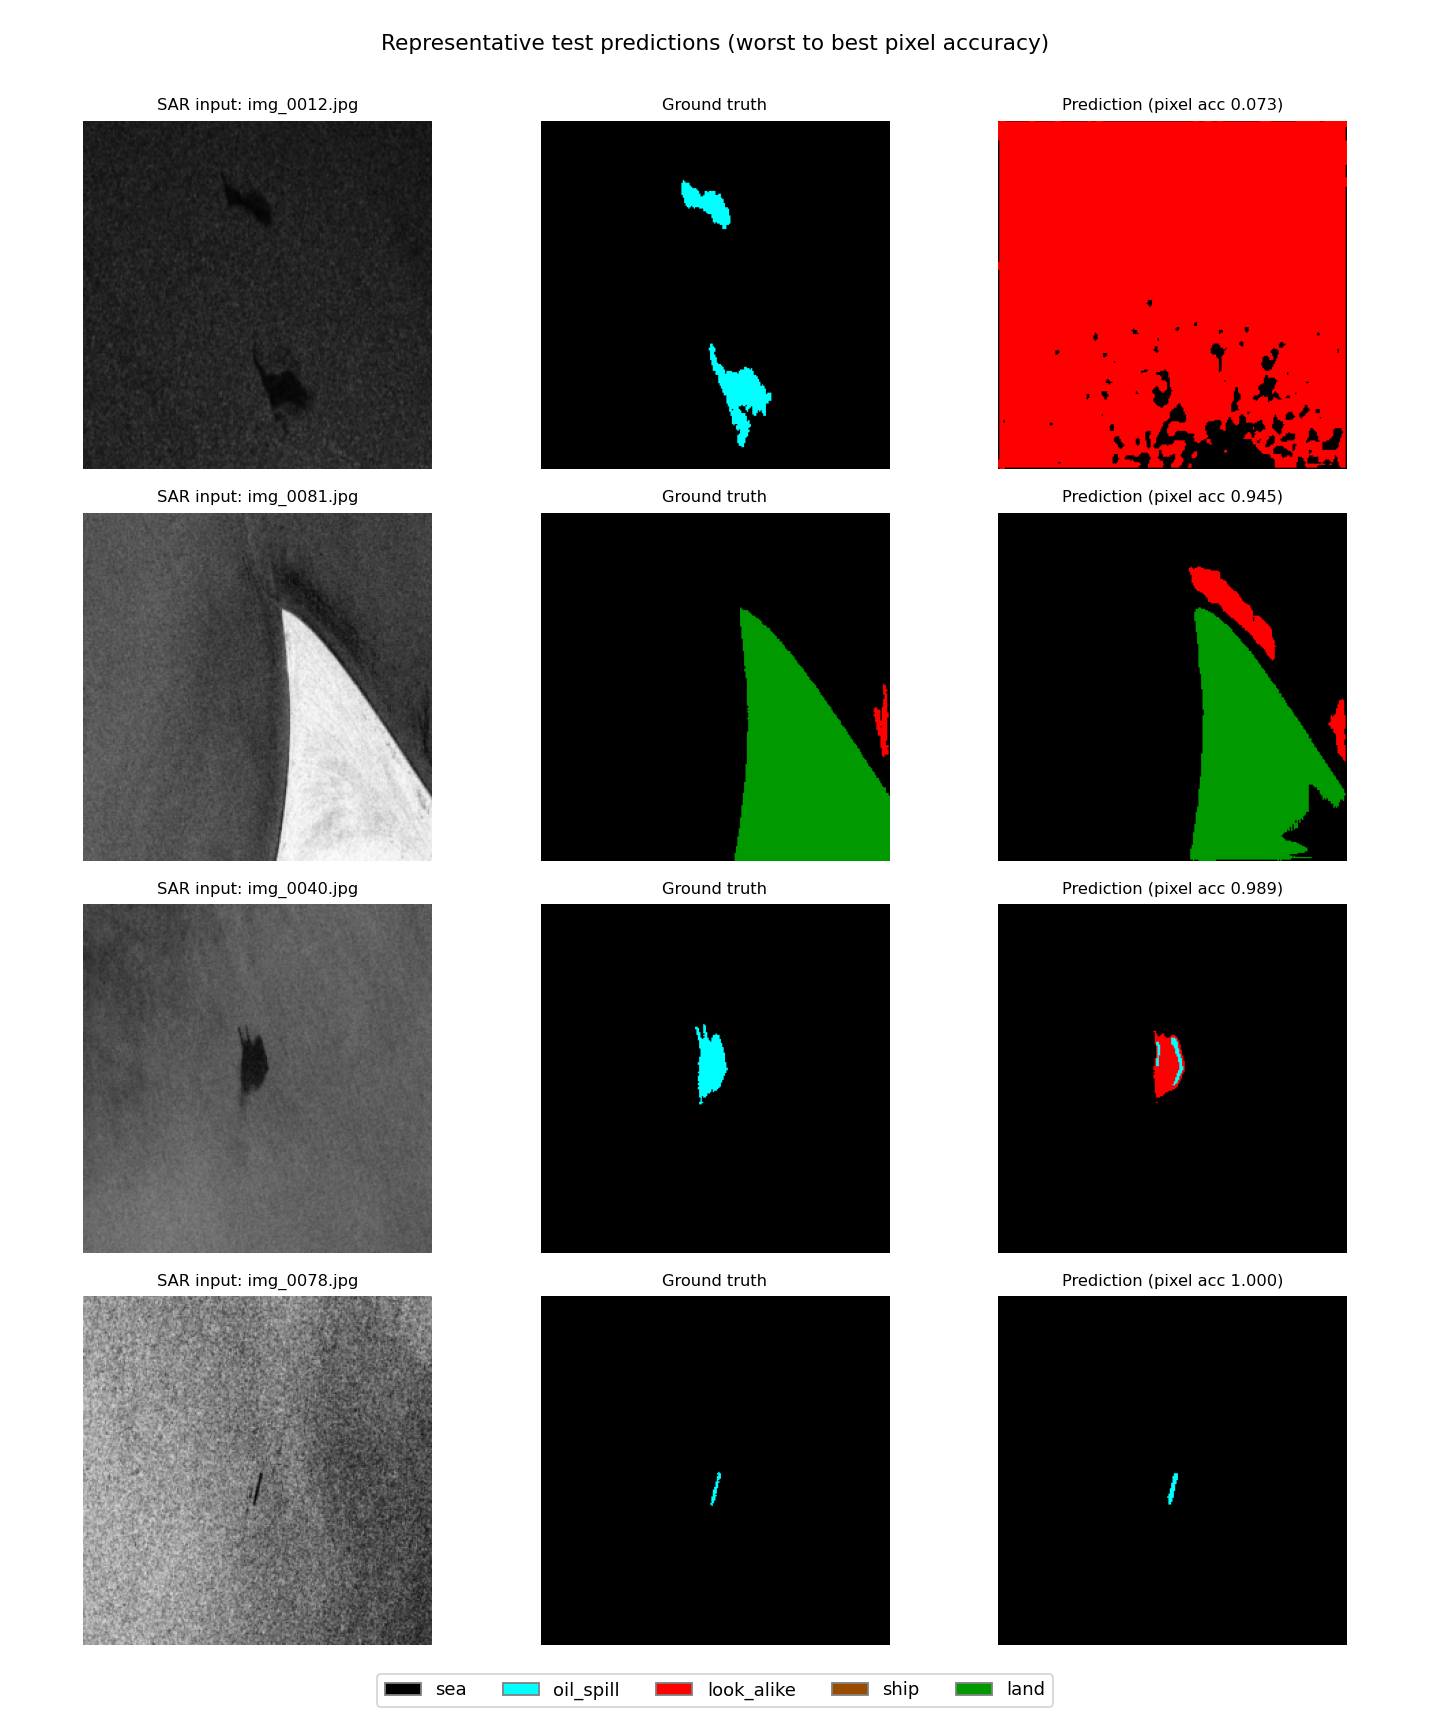

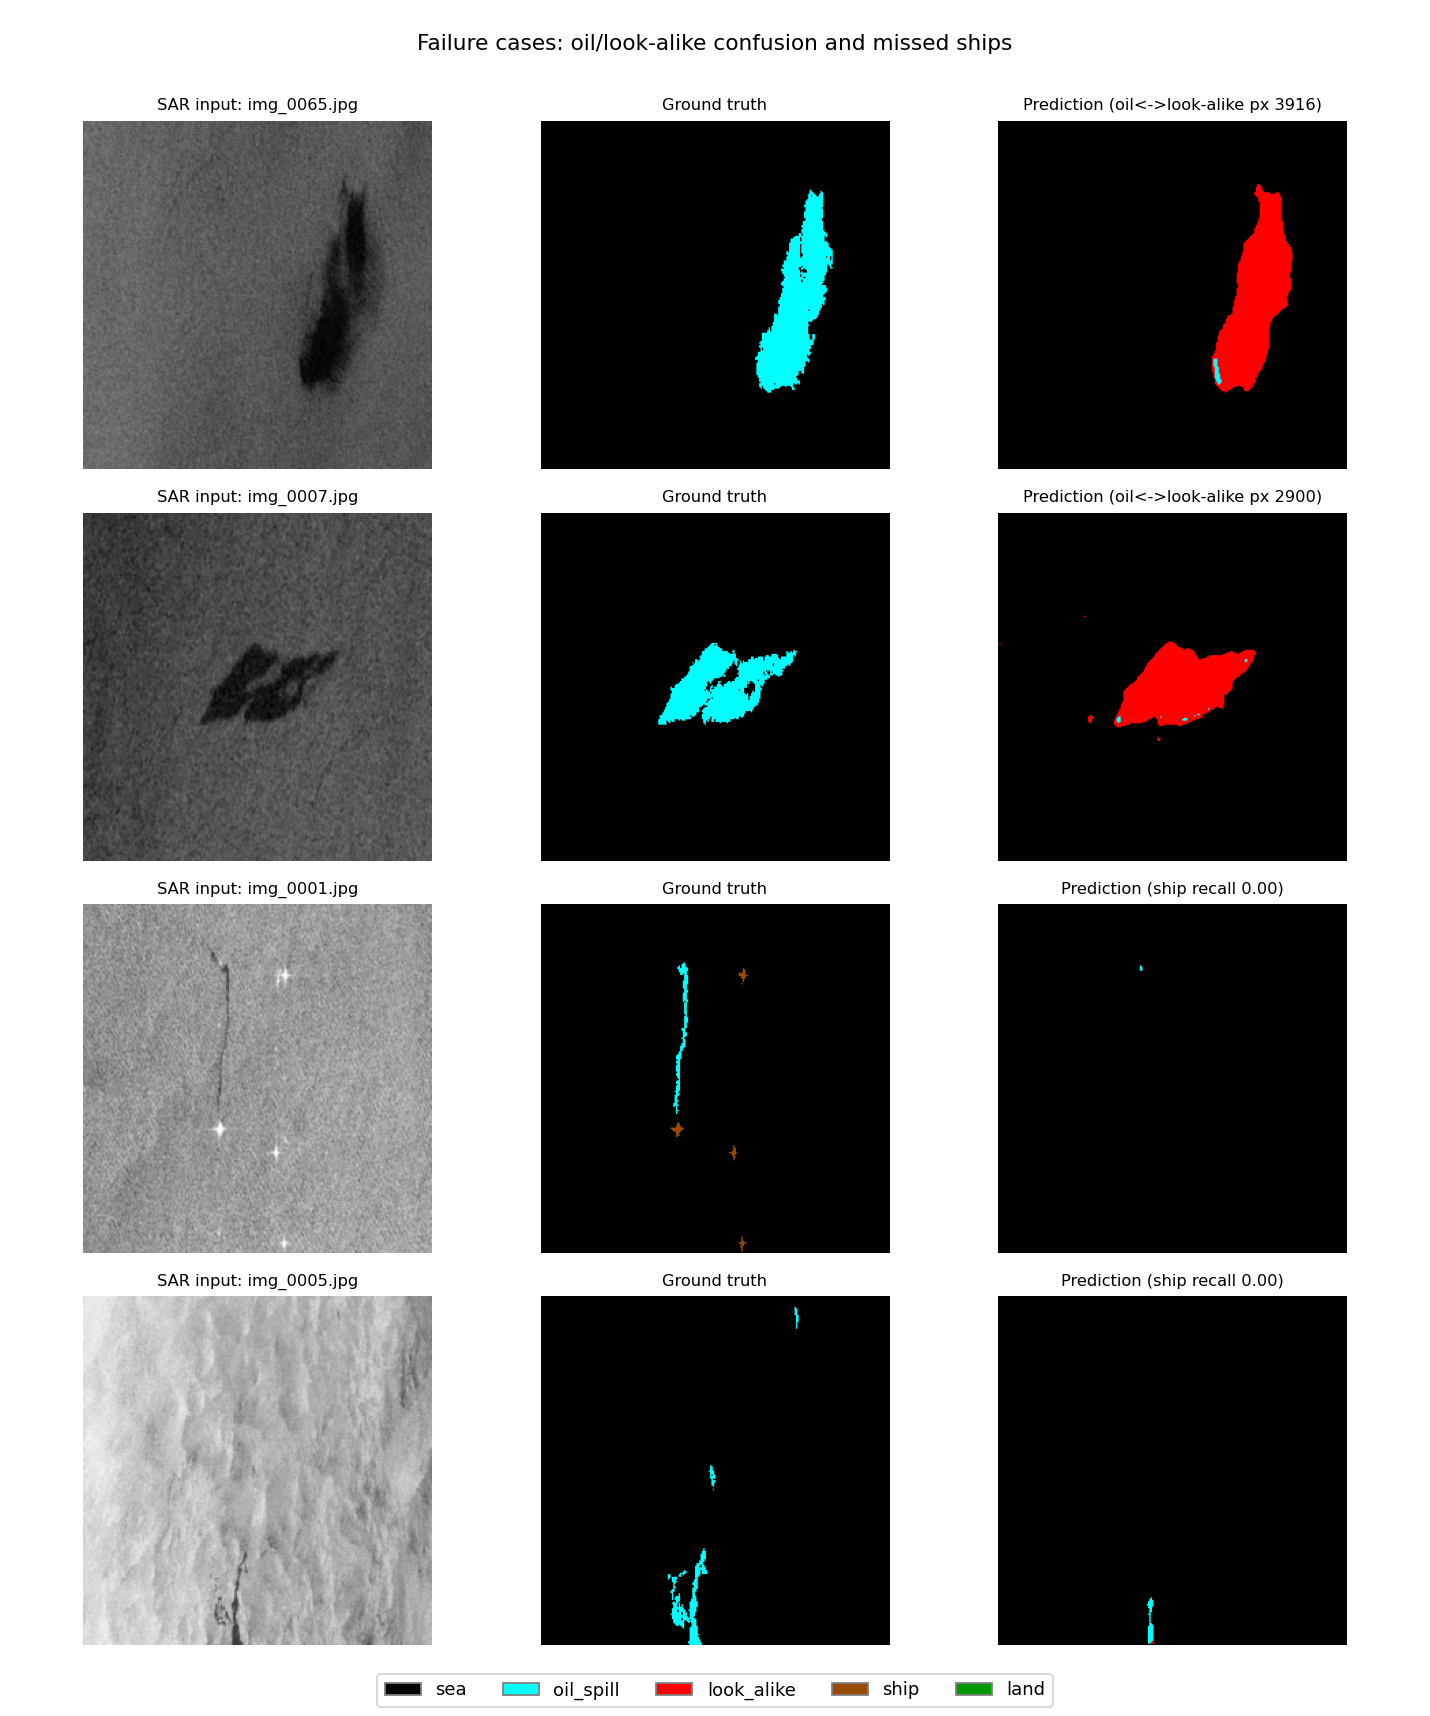

In [16]:
metrics = json.loads((OUT / 'test_eval/metrics.json').read_text())
table = pd.read_csv(OUT / 'test_eval/per_class_metrics.csv')
display(table.round(4))
print(f"mIoU {metrics['miou']:.4f} | mean Dice {metrics['mean_dice']:.4f} | "
      f"pixel accuracy {metrics['pixel_accuracy']:.4f} (supplementary)")
results_row = {'experiment': 'U-Net Exp.1 Cross-Entropy', 'mIoU': metrics['miou'],
               'mean_Dice': metrics['mean_dice'], 'pixel_acc': metrics['pixel_accuracy'],
               **{f'IoU_{n}': v for n, v in zip(metrics['class_names'], metrics['class_iou'])}}
pd.DataFrame([results_row]).to_csv(OUT / 'results_row.csv', index=False)  # for the team comparison table
display(pd.DataFrame([results_row]).round(4))
for name in ('confusion_matrix.png', 'predictions.png', 'failure_cases.png'):
    display(Show(str(OUT / 'test_eval' / name), width=900))

**Results discussion** *(fill in from your own run)*
- Per-class IoU vs. pixel accuracy: explain why high pixel accuracy does not imply good oil/ship segmentation.
- Confusion matrix: how much oil spill is predicted as look-alike (and vice versa)? How much ship is lost to sea?
- Failure cases: describe the shown oil/look-alike confusions and missed small ships.
- Limitations: resizing 1250×650 scenes to a square input distorts aspect ratio and shrinks small ships;
  GPU nondeterminism means reruns can differ slightly even with a fixed seed.

## 7. Saved artifacts

In [17]:
for p in sorted(OUT.rglob('*')):
    if p.is_file():
        print(f'{p.relative_to(WORK)}  ({p.stat().st_size / 1e6:.2f} MB)')

outputs/unet_ce/best_model.pt  (31.12 MB)
outputs/unet_ce/config.json  (0.02 MB)
outputs/unet_ce/history.csv  (0.01 MB)
outputs/unet_ce/history.json  (0.02 MB)
outputs/unet_ce/last_checkpoint.pt  (93.30 MB)
outputs/unet_ce/results_row.csv  (0.00 MB)
outputs/unet_ce/test_eval/confusion_matrix.png  (0.07 MB)
outputs/unet_ce/test_eval/failure_cases.png  (0.59 MB)
outputs/unet_ce/test_eval/metrics.json  (0.00 MB)
outputs/unet_ce/test_eval/per_class_metrics.csv  (0.00 MB)
outputs/unet_ce/test_eval/per_image.json  (0.02 MB)
outputs/unet_ce/test_eval/predictions.png  (0.62 MB)
outputs/unet_ce/training_curves.png  (0.23 MB)
outputs/unet_ce/training_summary.json  (0.00 MB)
